# Fault classification on the TEP: GCN vs FFNN
Each window of plant data (30 rows x 52 variables) is classified into one of 6 classes (normal + faults 1, 4, 8, 13, 14).

| Case | Model | Input | Graph |
|---|---|---|---|
| **Case 1** | GCN (3 layers, hidden width swept over 64-256) | all 52 variables | `adjacency_list_actuators` (33 connected nodes + 19 isolated) |
| **Case 2** | FFNN | all 52 variables, flattened | none |

GCN: node features = the 30-row time series of that variable; 3 `GCNConv` layers, mean pooling over nodes, linear head.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch_geometric.nn import GCNConv
from sklearn.metrics import confusion_matrix, classification_report, recall_score
warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# ex1_data_processing.ipynb uses paths relative to its own folder (../data, ../cache), so run this notebook from there
print("working directory:", Path.cwd())

C:\Users\keith\PycharmProjects\.venv\shared_env\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


device: cpu
working directory: C:\Users\keith\PycharmProjects\CN3105\Project\example_1


## Data
Runs the first three code cells of `ex1_data_processing.ipynb` (config, load/cache, standardise + window), giving `sets[...]` of windows shaped `(52 variables, 30 rows)` with their labels.

In [2]:
NB_DIR = Path("ex1_data_processing.ipynb")
nb_src = json.load(open(NB_DIR, encoding="utf-8"))
code_cells = [c for c in nb_src["cells"] if c["cell_type"] == "code"]
for c in code_cells[:3]:                       # config, data, windows (skip the demo print cell)
    exec("".join(c["source"]), globals())
# provides: sets["train"/"val"/"test"], CLASSES, FEATURES

train X(300, 500, 52)  31 MB  runs per class: {0: 50, 1: 50, 4: 50, 8: 50, 13: 50, 14: 50}
val   X(60, 500, 52)  6 MB  runs per class: {0: 10, 1: 10, 4: 10, 8: 10, 13: 10, 14: 10}
test  X(300, 960, 52)  60 MB  runs per class: {0: 50, 1: 50, 4: 50, 8: 50, 13: 50, 14: 50}


train  13900 windows; per class {0: 2400, 1: 2300, 4: 2300, 8: 2300, 13: 2300, 14: 2300}
val     2780 windows; per class {0: 480, 1: 460, 4: 460, 8: 460, 13: 460, 14: 460}
test   27700 windows; per class {0: 8200, 1: 3900, 4: 3900, 8: 3900, 13: 3900, 14: 3900}


## Graphs
Node numbering is 1-indexed: nodes 1-22 = `xmeas_1-22`, nodes 23-33 = `xmv_1-11` (actuators). `adjacency_list_actuators` only covers these 33 variables, so the 19 analyser measurements `xmeas_23-41` are added as **isolated nodes** (nodes 34-52, no edges besides the self-loop GCN adds).

Columns of the 52-variable data are therefore re-ordered to `[xmeas_1-22, xmv_1-11, xmeas_23-41]` so that node *i* = row *i-1*.

In [3]:
adjacency_list = [
    (1,6),(2,6),(3,6),(5,6),(16,6),(18,6),
    (4,15),(4,16),(4,18),
    (6,7),(6,8),(6,9),(7,8),(7,9),(8,9),(9,21),
    (9,22),(22,11),(7,13),
    (11,12),(11,13),(12,13),
    (13,20),(13,5),(13,10),(20,5),(20,10),(5,10),
    (12,14),(13,14),(14,15),(14,16),(14,18),
    (15,16),(15,18),(16,18),(15,17),(18,19),(16,19),
]
adjacency_list_actuators = adjacency_list + [
    (23,2),(24,3),(25,1),(26,4),(27,5),(27,20),(28,10),
    (29,14),(30,17),(31,19),(32,21),(33,22),
]

def make_edge_index(edges):
    ei = torch.tensor(edges).T - 1                       # 0-indexed
    return torch.cat([ei, ei.flip(0)], dim=1)            # undirected

# column order: xmeas_1-22, xmv_1-11, xmeas_23-41
col = {n: i for i, n in enumerate(FEATURES)}
ORDER = ([col[f"xmeas_{i}"] for i in range(1, 23)] + [col[f"xmv_{i}"] for i in range(1, 12)]
         + [col[f"xmeas_{i}"] for i in range(23, 42)])
NODE_NAMES = [FEATURES[i] for i in ORDER]
assert len(ORDER) == 52 and sorted(ORDER) == list(range(52))

ei_52 = make_edge_index(adjacency_list_actuators)
print("graph: 52 nodes (33 connected + 19 isolated),", ei_52.shape[1], "directed edges")

graph: 52 nodes (33 connected + 19 isolated), 102 directed edges


In [4]:
def to_tensors(ds):
    Xw, y = ds.batch(np.arange(len(ds)))                 # (B, 52, 30), (B,)
    return torch.from_numpy(np.ascontiguousarray(Xw[:, ORDER])), torch.from_numpy(y)

Xtr, ytr = to_tensors(sets["train"])
Xva, yva = to_tensors(sets["val"])
Xte, yte = to_tensors(sets["test"])
print("train", tuple(Xtr.shape), " val", tuple(Xva.shape), " test", tuple(Xte.shape))

train (13900, 52, 30)  val (2780, 52, 30)  test (27700, 52, 30)


## Shared training / evaluation code

In [5]:
EPOCHS, BS, LR = 40, 256, 1e-3
N_CLASSES = len(CLASSES)
results = {}          # case name -> dict(hist, pred, val_acc, test_acc, params, layers)
width_results = {}    # case name -> {hidden: dict(...)} from the GCN width sweep
N_LAYERS = 3                  # number of GCNConv layers (= message-passing hops), fixed
WIDTHS = [64, 128, 256]  # hidden widths to try

@torch.no_grad()
def predict(model, X, bs=2048):
    model.eval()
    return torch.cat([model(X[i:i+bs].to(device)).argmax(1).cpu() for i in range(0, len(X), bs)])

def run_case(name, model, n_nodes, seed=0):
    # Train `model` on the first n_nodes node-rows of every window; keep the best epoch on val.
    torch.manual_seed(seed)
    model = model.to(device)
    Xt, Xv, Xs = Xtr[:, :n_nodes], Xva[:, :n_nodes], Xte[:, :n_nodes]
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
    hist = {"loss": [], "val_acc": []}
    best_acc, best_state = -1, None
    for ep in range(EPOCHS):
        model.train()
        perm = torch.randperm(len(Xt))
        tot = 0.0
        for i in range(0, len(perm), BS):
            idx = perm[i:i+BS]
            opt.zero_grad()
            loss = F.cross_entropy(model(Xt[idx].to(device)), ytr[idx].to(device))
            loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        va = (predict(model, Xv) == yva).float().mean().item()
        hist["loss"].append(tot / len(perm)); hist["val_acc"].append(va)
        if va > best_acc:
            best_acc, best_state = va, {k: v.clone() for k, v in model.state_dict().items()}
        if (ep + 1) % 5 == 0 or ep == 0:
            print(f"[{name}] epoch {ep+1:2d}  loss {hist['loss'][-1]:.4f}  val acc {va:.4f}")
    model.load_state_dict(best_state)
    pred = predict(model, Xs).numpy()
    res = dict(hist=hist, pred=pred, val_acc=best_acc, test_acc=(pred == yte.numpy()).mean(),
               params=sum(p.numel() for p in model.parameters()))
    print(f"[{name}] best val acc {best_acc:.4f}   test acc {res['test_acc']:.4f}   params {res['params']:,}")
    return res

class GCNClassifier(nn.Module):
    # n_layers x GCNConv (each layer = one hop) + mean pool over nodes + linear head. Input (B, N, F), fixed graph.
    def __init__(self, edge_index, in_dim, hidden=64, n_layers=2, p=0.2):
        super().__init__()
        self.register_buffer("edge_index", edge_index)
        dims = [in_dim] + [hidden] * n_layers
        self.convs = nn.ModuleList(GCNConv(a, b) for a, b in zip(dims[:-1], dims[1:]))
        self.drop = nn.Dropout(p)
        self.head = nn.Linear(hidden, N_CLASSES)

    def forward(self, x):
        h = x
        for i, conv in enumerate(self.convs):
            h = F.relu(conv(h, self.edge_index))
            if i < len(self.convs) - 1:
                h = self.drop(h)
        return self.head(h.mean(dim=1))

def gcn_width_sweep(case, edge_index, n_nodes):
    # Train a GCN (N_LAYERS layers) for every hidden width in WIDTHS, keep the one with the best validation accuracy.
    width_results[case] = {}
    for H in WIDTHS:
        model = GCNClassifier(edge_index, in_dim=Xtr.shape[-1], hidden=H, n_layers=N_LAYERS)
        res = run_case(f"{case}, hidden {H}", model, n_nodes)
        res["hidden"] = H
        width_results[case][H] = res
    best = max(width_results[case], key=lambda H: width_results[case][H]["val_acc"])
    results[case] = width_results[case][best]
    print(f"==> {case}: best width by validation accuracy = {best} "
          f"(val {results[case]['val_acc']:.4f}, test {results[case]['test_acc']:.4f})")

class FFNN(nn.Module):
    # MLP on the flattened window (52 x 30 = 1560 inputs).
    def __init__(self, in_dim, hidden=(256, 128), p=0.2):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(p)]
            d = h
        self.net = nn.Sequential(*layers, nn.Linear(d, N_CLASSES))

    def forward(self, x):
        return self.net(x.flatten(1))

# Case 1: GCN, all 52 variables, `adjacency_list_actuators`
Nodes = 22 sensors + 11 actuators (connected per `adjacency_list_actuators`) + 19 analyser measurements (isolated). The GCN has a fixed 3 layers (= 3 hops of message passing, the best depth in an earlier 2-5 layer sweep); the hidden width is swept over `WIDTHS`, and the width with the best validation accuracy is used for the comparison.

In [6]:
gcn_width_sweep("Case 1: GCN (52 vars)", ei_52, n_nodes=52)

[Case 1: GCN (52 vars), hidden 64] epoch  1  loss 1.4941  val acc 0.4335


[Case 1: GCN (52 vars), hidden 64] epoch  5  loss 0.6379  val acc 0.7896


[Case 1: GCN (52 vars), hidden 64] epoch 10  loss 0.5422  val acc 0.8061


[Case 1: GCN (52 vars), hidden 64] epoch 15  loss 0.4748  val acc 0.8252


[Case 1: GCN (52 vars), hidden 64] epoch 20  loss 0.4318  val acc 0.8554


[Case 1: GCN (52 vars), hidden 64] epoch 25  loss 0.4027  val acc 0.8637


... (20 outputs left out)

[Case 1: GCN (52 vars), hidden 256] epoch 30  loss 0.2561  val acc 0.9245


[Case 1: GCN (52 vars), hidden 256] epoch 35  loss 0.2411  val acc 0.9216


[Case 1: GCN (52 vars), hidden 256] epoch 40  loss 0.2106  val acc 0.9367


[Case 1: GCN (52 vars), hidden 256] best val acc 0.9381   test acc 0.9460   params 141,062
==> Case 1: GCN (52 vars): best width by validation accuracy = 256 (val 0.9381, test 0.9460)


## GCN width study (Case 1)
Accuracy against the hidden width of the 3-layer GCN (parameter count on the top axis labels).

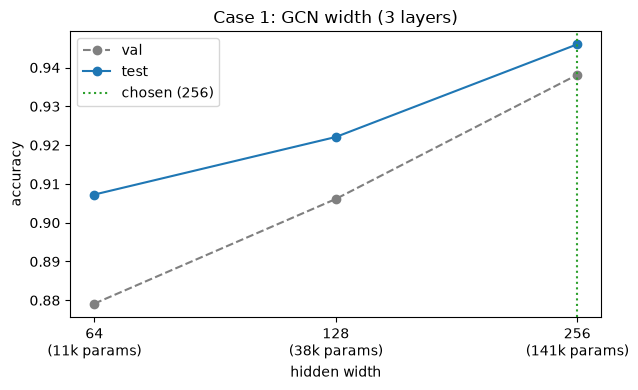

In [7]:
runs = width_results["Case 1: GCN (52 vars)"]
Hs = list(runs)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(range(len(Hs)), [runs[H]["val_acc"] for H in Hs], "o--", color="gray", label="val")
ax.plot(range(len(Hs)), [runs[H]["test_acc"] for H in Hs], "o-", color="tab:blue", label="test")
best = results["Case 1: GCN (52 vars)"]["hidden"]
ax.axvline(Hs.index(best), color="tab:green", ls=":", label=f"chosen ({best})")
ax.set_xticks(range(len(Hs))); ax.set_xticklabels([f"{H}\n({runs[H]['params'] / 1e3:.0f}k params)" for H in Hs])
ax.set_xlabel("hidden width"); ax.set_ylabel("accuracy"); ax.set_title("Case 1: GCN width (3 layers)"); ax.legend()
plt.tight_layout(); plt.show()

# Case 2: FFNN, all 52 variables
No graph: the whole 52 x 30 window is flattened and fed to an MLP (256-128-6).

In [8]:
results["Case 2: FFNN (52 vars)"] = run_case("Case 2: FFNN (52 vars)", FFNN(in_dim=52 * Xtr.shape[-1]), n_nodes=52)

[Case 2: FFNN (52 vars)] epoch  1  loss 0.4012  val acc 0.9820


[Case 2: FFNN (52 vars)] epoch  5  loss 0.0488  val acc 0.9838


[Case 2: FFNN (52 vars)] epoch 10  loss 0.0258  val acc 0.9899


[Case 2: FFNN (52 vars)] epoch 15  loss 0.0223  val acc 0.9842


[Case 2: FFNN (52 vars)] epoch 20  loss 0.0148  val acc 0.9921


[Case 2: FFNN (52 vars)] epoch 25  loss 0.0186  val acc 0.9896


[Case 2: FFNN (52 vars)] epoch 30  loss 0.0162  val acc 0.9799


[Case 2: FFNN (52 vars)] epoch 35  loss 0.0207  val acc 0.9899


[Case 2: FFNN (52 vars)] epoch 40  loss 0.0150  val acc 0.9914
[Case 2: FFNN (52 vars)] best val acc 0.9924   test acc 0.9930   params 433,286


# Comparison of both cases

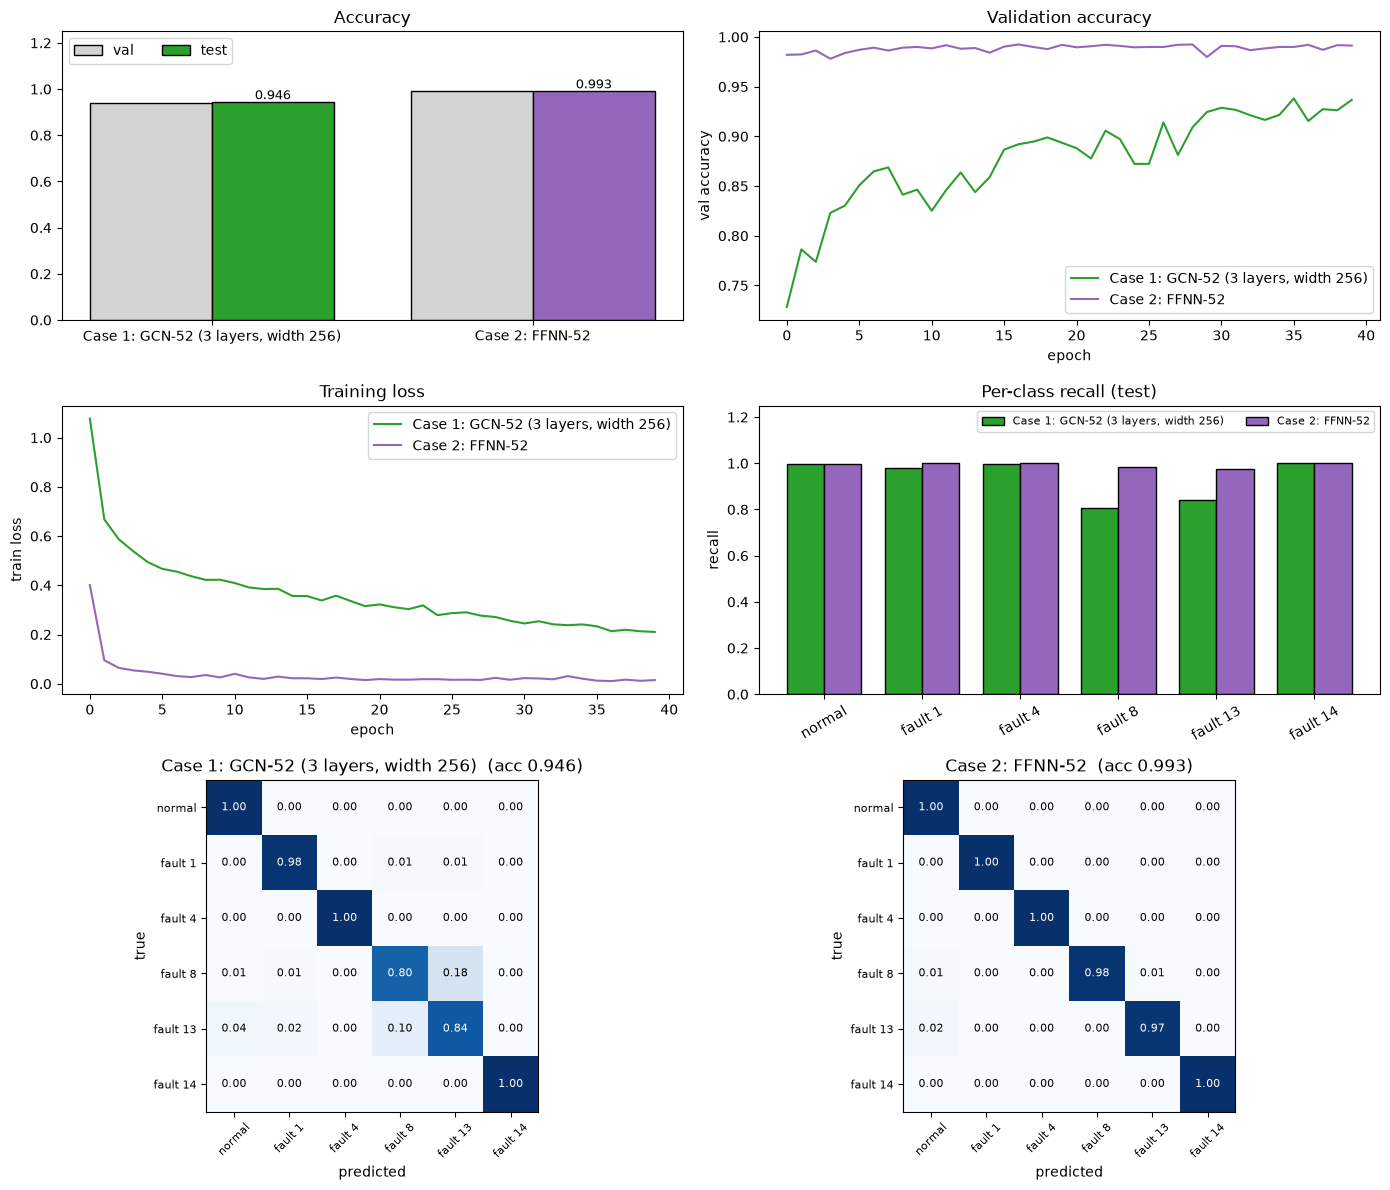

case                             params  val acc  test acc
Case 1: GCN (52 vars)           141,062   0.9381    0.9460
Case 2: FFNN (52 vars)          433,286   0.9924    0.9930


In [9]:
names = list(results)
r1 = results[names[0]]
short = [f"Case 1: GCN-52 (3 layers, width {r1['hidden']})", "Case 2: FFNN-52"]
cls_names = [("normal" if c == 0 else f"fault {c}") for c in CLASSES]
true = yte.numpy()
colors = ["tab:green", "tab:purple"]
K = len(names)

fig = plt.figure(figsize=(14, 12))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.15])

# (a) accuracy
ax = fig.add_subplot(gs[0, 0])
x = np.arange(K); w = 0.38
ax.bar(x - w/2, [results[n]["val_acc"] for n in names], w, label="val", color="lightgray", edgecolor="k")
ax.bar(x + w/2, [results[n]["test_acc"] for n in names], w, label="test", color=colors, edgecolor="k")
for xi, n in zip(x, names):
    ax.text(xi + w/2, results[n]["test_acc"] + 0.01, f"{results[n]['test_acc']:.3f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(short); ax.set_ylim(0, 1.25); ax.set_title("Accuracy"); ax.legend(loc="upper left", ncol=2)

# (b) validation accuracy curves
ax = fig.add_subplot(gs[0, 1])
for n, c, s in zip(names, colors, short):
    ax.plot(results[n]["hist"]["val_acc"], color=c, label=s)
ax.set_xlabel("epoch"); ax.set_ylabel("val accuracy"); ax.set_title("Validation accuracy"); ax.legend()

# (c) training loss
ax = fig.add_subplot(gs[1, 0])
for n, c, s in zip(names, colors, short):
    ax.plot(results[n]["hist"]["loss"], color=c, label=s)
ax.set_xlabel("epoch"); ax.set_ylabel("train loss"); ax.set_title("Training loss"); ax.legend()

# (d) per-class recall
ax = fig.add_subplot(gs[1, 1])
recalls = [recall_score(true, results[n]["pred"], average=None, labels=range(N_CLASSES)) for n in names]
w = 0.38
for k, (r, c, s) in enumerate(zip(recalls, colors, short)):
    ax.bar(np.arange(N_CLASSES) + (k - 0.5) * w, r, w, color=c, label=s, edgecolor="k")
ax.set_xticks(np.arange(N_CLASSES)); ax.set_xticklabels(cls_names, rotation=30)
ax.set_ylim(0, 1.25); ax.set_ylabel("recall"); ax.set_title("Per-class recall (test)"); ax.legend(ncol=2, fontsize=8)

# (e) confusion matrices
for j, (n, s) in enumerate(zip(names, short)):
    ax = fig.add_subplot(gs[2, j])
    cm = confusion_matrix(true, results[n]["pred"], normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for r in range(N_CLASSES):
        for c in range(N_CLASSES):
            ax.text(c, r, f"{cm[r, c]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[r, c] > .5 else "black")
    ax.set_xticks(range(N_CLASSES)); ax.set_xticklabels(cls_names, rotation=45, fontsize=8)
    ax.set_yticks(range(N_CLASSES)); ax.set_yticklabels(cls_names, fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{s}  (acc {results[n]['test_acc']:.3f})")
plt.tight_layout(); plt.show()

print(f"{'case':28s} {'params':>10s} {'val acc':>8s} {'test acc':>9s}")
for n in names:
    print(f"{n:28s} {results[n]['params']:>10,} {results[n]['val_acc']:>8.4f} {results[n]['test_acc']:>9.4f}")